# Natural frequency analysis of a cylinder

An isotropic circular cylindrical shell of `Quad4` elements, supported at
both ends by shear diaphragms, whose lowest frequencies are compared with the
three-dimensional elasticity solution tabulated by Leissa (1973). The mass
matrix is assembled with `update_M` and the frequencies are computed with
`natural_frequency`, see
[Linear buckling and natural frequencies](../eigenvalue_analyses.rst). The
docstring of the test gives the measured convergence to the tabulated values
(`tests/test_quad4_natural_freq_cylinder.py`); the full references are at the
end of the notebook.

In [1]:
import os
import sys

sys.path.insert(0, os.path.join('..', 'tests'))

import time
import numpy as np
import pytest
from numpy import isclose
from scipy.sparse import coo_matrix
from pyfe3d import DOF, DOUBLE, INT, Quad4, Quad4Data, Quad4Probe
from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d.solver import natural_frequency

import pyvista as pv

# NOTE static images of the PyVista figures, stored in the notebook
pv.set_jupyter_backend('static')

## What the test verifies, and against what

The cylinder has $R = 250$ mm, $h = R/20$, $L = 4 R$, $E = 70$ GPa, $\nu =
0.3$ and $\rho = 2700$ kg/m$^3$, with `ntheta = 48*refinement` nearly square
elements around the circumference. The shear diaphragms of Leissa (1973,
Eq. (2.33), p. 43), $v = w = N_x = M_x = 0$ at both ends, are imposed by
holding the radial and circumferential translations of the edge nodes; one
node is held axially to remove the rigid translation. The frequencies
$\omega_n$ of $(\boldsymbol{K}_{C0} - \omega_n^2 \boldsymbol{M}) \boldsymbol{u}
= \boldsymbol{0}$ are given as the frequency parameter of his Eq. (2.26),
p. 38,

$$
\Omega^2 = \frac{\rho (1 - \nu^2) R^2 \omega_n^2}{E}
$$

## The reference values

Table 2.8 of Leissa (1973, Sec. 2.3, p. 55) gives the lowest frequency
parameters of the three-dimensional theory of elasticity, shear diaphragms at
both ends and $\nu = 0.3$. For $R/h = 20$ and $l/(m R) = 4$:

| $n$ | $\Omega$ |
|----|----------|
| 2 | 0.121249 |
| 3 | 0.129881 |

every other entry of that column being higher ($n = 1$: 0.257011, $n = 4$:
0.219098). A cylinder of length $4 R$ vibrating with $m = 1$ axial half-wave
therefore has the $n = 2$ pair as its two lowest frequencies and the $n = 3$
pair as the next two: each circumferential wave number $n \ge 1$ gives two
modes of the same frequency, $\cos n\theta$ and $\sin n\theta$. The test checks
the pairs, that the frequencies are above the table (they converge from
above), within grade A, 2 %, of MacNeal and Harder (1985, p. 14), and, for
`refinement` 1 and 2, equal to the values pre-determined by the test with
`rtol = 1e-4`. A shell theory differs from the elasticity solution: Table 2.6
(concluded), p. 53, of the same reference puts the Flügge shell theory 0.40 %
above it for $n = 3$ at this geometry.

In [2]:
@pytest.mark.slow
def test_linear_nat_freq_cylinder(mode=0, plot_pyvista=False, refinement=1):
    r"""Lowest natural frequencies of an isotropic circular cylindrical shell
    supported at both ends by shear diaphragms

    The reference is Leissa, A. W., Vibration of Shells, NASA SP-288, 1973,
    Sec. 2.3, Table 2.8, p. 55: lowest frequency parameters according to the
    three-dimensional theory of elasticity, SD-SD supports, ``nu = 0.3``. For
    ``R/h = 20`` and ``l/mR = 4`` the table gives

        n = 2    Omega = 0.121249
        n = 3    Omega = 0.129881

    and every other entry of that column is higher, ``n = 1`` being 0.257011
    and ``n = 4`` 0.219098. The frequency parameter is defined by Eq. (2.26),
    p. 38, ``Omega**2 = rho*(1 - nu**2)*R**2*omega**2/E``, and the shear
    diaphragm supports by Eq. (2.33), p. 43, ``v = w = N_x = M_x = 0`` at both
    ends. A cylinder of length ``L = 4*R`` vibrating with ``m = 1`` axial
    half-wave therefore has the ``n = 2`` pair as its two lowest frequencies
    and the ``n = 3`` pair as the next two.

    The frequencies converge from above. Relative errors of the ``n = 2`` and
    ``n = 3`` pairs against the table, for ``ntheta`` elements around the
    circumference and nearly square elements::

        ntheta    n = 2      n = 3
           16    +3.68 %   +16.06 %
           24    +1.65 %    +6.58 %
           32    +0.87 %    +3.55 %
           48    +0.36 %    +1.48 %
           64    +0.18 %    +0.78 %
           96    +0.05 %    +0.28 %

    so the element converges to the three-dimensional solution: Table 2.6
    (concluded), p. 53, of the same reference puts the Flugge shell theory
    0.40 % above the elasticity value for ``n = 3`` at this geometry, and at
    ``ntheta = 96`` the error is already below that.

    From ``ntheta = 48``, the default ``refinement=1``, the errors are within
    grade A, 2 per cent, of MacNeal, R. H., and Harder, R. L., "A proposed
    standard set of problems to test finite element accuracy", Finite
    Elements in Analysis and Design, 1(1), 3-20, 1985, p. 14, which the test
    checks. It also compares Omega with the values pre-determined by this
    same test, with a tolerance for the round-off of other platforms only;
    wall times on a machine shared with other jobs::

        refinement  ntheta  elements   n = 2       n = 3       time
            1         48      1440    0.12169936  0.13185390    1 s
            2         96      5760    0.12132261  0.13026712   11 s

    with the default ``shear_model = 1`` of Quad4 since 0.12.0, the assumed
    transverse shear strains of the MITC4 element (measured on 2026-10-30);
    the one-point transverse shear of ``shear_model = 0`` gave 0.12168186,
    0.13180857, 0.12131378 and 0.13024089, up to 0.034 per cent less

    """
    data = Quad4Data()
    probe = Quad4Probe()

    # NOTE geometry of Table 2.8 of Leissa (1973): R/h = 20 and l/mR = 4 with
    #      m = 1. The frequency parameter Omega is dimensionless, so only
    #      R/h, L/R and nu matter; E and rho are arbitrary
    R = 0.250 # m
    h = R/20 # m
    L = 4*R # m
    b = 2*np.pi*R # m
    E = 70.e9 # Pa
    nu = 0.3
    rho = 2.7e3 # kg/m3

    ntheta = 48*refinement # circumferential
    nlength = int(round(ntheta*L/b))
    if nlength % 2 == 0:
        nlength += 1
    print('ntheta', ntheta)
    print('nlength', nlength)

    prop = isotropic_plate(thickness=h, E=E, nu=nu, rho=rho)

    nids = 1 + np.arange(nlength*(ntheta+1))
    nids_mesh = nids.reshape(nlength, ntheta+1)
    nids_mesh[:, -1] = nids_mesh[:, 0]
    nids = np.unique(nids_mesh)
    nid_pos = dict(zip(nids, np.arange(len(nids))))

    zlin = np.linspace(0, L, nlength)
    thetatmp = np.linspace(0, 2*np.pi, ntheta+1)
    thetalin = np.linspace(0, 2*np.pi-(thetatmp[-1] - thetatmp[-2]), ntheta)[::-1]
    zmesh, thetamesh = np.meshgrid(zlin, thetalin)
    zmesh = zmesh.T
    thetamesh = thetamesh.T
    xmesh = np.cos(thetamesh)*R
    ymesh = np.sin(thetamesh)*R

    ncoords = np.vstack((xmesh.flatten(), ymesh.flatten(), zmesh.flatten())).T
    ncoords_flatten = ncoords.flatten()
    x = ncoords[:, 0]
    y = ncoords[:, 1]
    z = ncoords[:, 2]

    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()

    num_elements = len(n1s)
    print('num_elements', num_elements)

    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    Mr = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=INT)
    Mc = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=INT)
    Mv = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    N = DOF*nlength*ntheta

    quads = []
    init_k_KC0 = 0
    init_k_M = 0
    t0 = time.time()
    for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
        quad = Quad4(probe)
        quad.n1 = n1
        quad.n2 = n2
        quad.n3 = n3
        quad.n4 = n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = init_k_KC0
        quad.init_k_M = init_k_M
        quad.update_rotation_matrix(ncoords_flatten, 0., 0., 1.)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quad.update_M(Mr, Mc, Mv, prop, mtype=0) # consistent mass
        quads.append(quad)
        init_k_KC0 += data.KC0_SPARSE_SIZE
        init_k_M += data.M_SPARSE_SIZE

    print('elements created', time.time()-t0)

    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    M = coo_matrix((Mv, (Mr, Mc)), shape=(N, N)).tocsc()

    print('sparse KC0 and M created')

    bk = np.zeros(N, dtype=bool)

    # NOTE shear diaphragms, Eq. (2.33) of Leissa (1973): the radial and the
    #      circumferential displacements vanish at both ends, which for a
    #      cylinder along the global z axis are the global x and y
    #      translations, while the axial displacement and the rotations are
    #      left free (N_x = M_x = 0)
    edges = isclose(z, 0) | isclose(z, L)
    bk[0::DOF][edges] = True
    bk[1::DOF][edges] = True
    # NOTE removing the rigid axial translation by holding the axial
    #      displacement of a single node at mid-length, where the axial
    #      displacement of every mode with m = 1 vanishes, u ~ cos(pi*z/L)
    middle = np.where(isclose(z, L/2))[0]
    bk[2::DOF][middle[0]] = True

    bu = ~bk

    KC0uu = KC0[bu, :][:, bu]
    Muu = M[bu, :][:, bu]

    num_eig = max(mode+1, 6)
    eigvecs = np.zeros((N, num_eig))
    # NOTE pyfe3d.solver.natural_frequency equilibrates the diagonal
    #      before calling the eigensolver and returns the circular
    #      frequencies already sorted
    omegan, eigvecsu = natural_frequency(KC0uu, Muu, num_eigvalues=num_eig, tol=1e-8)
    eigvecs[bu] = eigvecsu

    print('natural frequency analysis OK')
    print('omegan =', omegan)

    # NOTE frequency parameter of Leissa (1973), Eq. (2.26)
    Omega = omegan*R*np.sqrt(rho*(1 - nu**2)/E)
    print('Omega =', Omega)

    # NOTE Leissa (1973), Table 2.8, R/h = 20, l/mR = 4
    Omega_n2 = 0.121249
    Omega_n3 = 0.129881

    # NOTE each circumferential wave number n >= 1 gives a pair of modes,
    #      cos(n*theta) and sin(n*theta), with the same frequency
    assert isclose(Omega[0], Omega[1], rtol=1e-6)
    assert isclose(Omega[2], Omega[3], rtol=1e-6)

    # NOTE convergence is from above, and from ntheta = 48 the errors of
    #      the docstring are within grade A of MacNeal and Harder (1985),
    #      p. 14, 2 per cent
    assert Omega[0] > Omega_n2
    assert Omega[2] > Omega_n3
    assert isclose(Omega[0], Omega_n2, rtol=0.02)
    assert isclose(Omega[2], Omega_n3, rtol=0.02)

    # NOTE Omega of the n = 2 and n = 3 pairs pre-determined with this same
    #      test at the same refinement, see the table of the docstring. The
    #      tolerance, rtol = 1e-4, is for the round-off of other platforms
    #      and solvers only
    predetermined = {
        1: (0.12169936, 0.13185390),
        2: (0.12132261, 0.13026712),
    }
    if refinement in predetermined:
        assert isclose(Omega[0], predetermined[refinement][0], rtol=1e-4)
        assert isclose(Omega[2], predetermined[refinement][1], rtol=1e-4)

    if plot_pyvista:
        import pyvista as pv

        contour_colorscale = 'coolwarm'
        background = 'gray'
        contour_label = 'Radial displacement'
        vector = eigvecs[:, mode]
        contour_vec = np.sqrt(vector[0::DOF]**2 + vector[1::DOF]**2)

        plotter = pv.Plotter(off_screen=False)
        faces_quad = []
        for q in quads:
            faces_quad.append([4, nid_pos[q.n1], nid_pos[q.n2], nid_pos[q.n3], nid_pos[q.n4]])
        faces_quad = np.array(faces_quad)
        quad_plot = pv.PolyData(ncoords, faces_quad)
        quad_plot[contour_label] = contour_vec
        plotter.add_mesh(quad_plot, scalars=contour_label,
                cmap=contour_colorscale, edge_color='black', show_edges=True,
                line_width=1.)
        #NOTE plotting coordinate system
        xaxis = pv.Arrow(start=(0, 0, 0), direction=(1, 0, 0), scale=R/3)
        plotter.add_mesh(xaxis, color='blue')
        yaxis = pv.Arrow(start=(0, 0, 0), direction=(0, 1, 0), scale=R/3)
        plotter.add_mesh(yaxis, color='yellow')
        zaxis = pv.Arrow(start=(0, 0, 0), direction=(0, 0, 1), scale=R/3)
        plotter.add_mesh(zaxis, color='green')

        plotter.set_background(background)
        plotter.parallel_projection = False
        plotter.show()

The first vibration mode, plotted with PyVista using `refinement=2`:

ntheta 96
nlength 61
num_elements 5760


elements created 1.920151948928833


sparse KC0 and M created


natural frequency analysis OK
omegan = [2590.28879526 2590.28879526 2781.25784595 2781.25784595 3284.50630624
 4709.17401518]
Omega = [0.12132261 0.12132261 0.13026712 0.13026712 0.15383801 0.22056587]


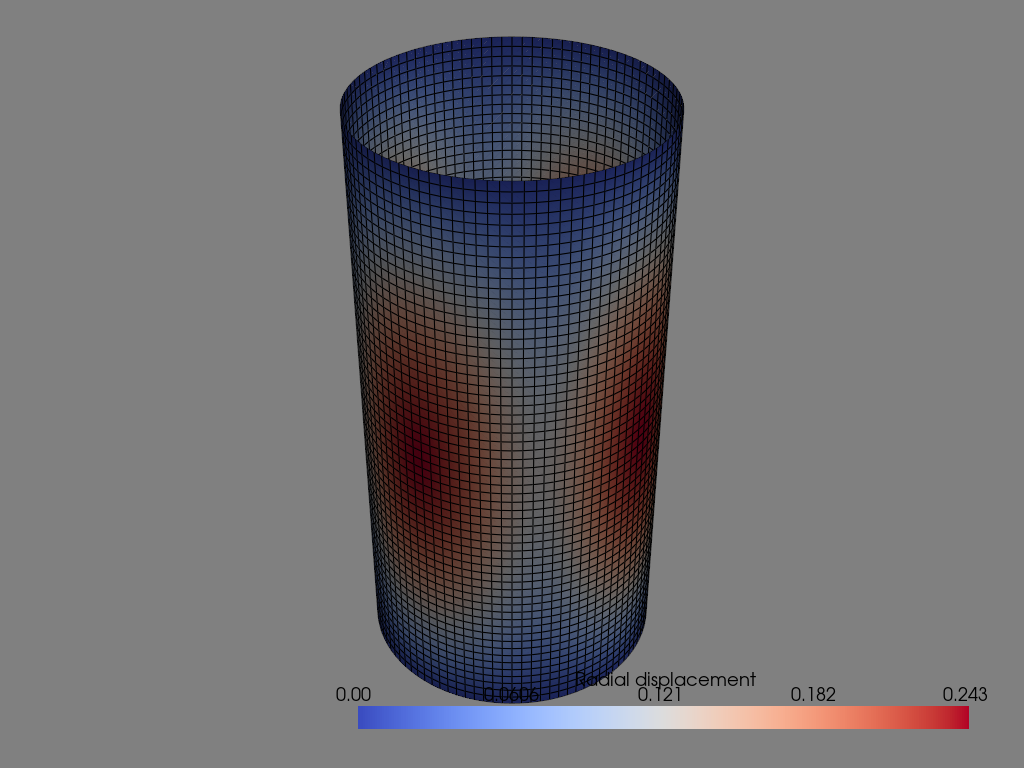

In [3]:
test_linear_nat_freq_cylinder(mode=0, plot_pyvista=True, refinement=2)

With `refinement=2`, 96 elements around the circumference, the parameters of
the $n = 2$ and $n = 3$ pairs are 0.06 % and 0.30 % above Table 2.8, the
latter already below the difference between the Flügge theory and the
elasticity solution.

## References

- Leissa, A. W., Vibration of Shells, NASA SP-288, 1973.
- MacNeal, R. H. and Harder, R. L., A proposed standard set of problems to
  test finite element accuracy, Finite Elements in Analysis and Design,
  1(1), 3-20, 1985. https://doi.org/10.1016/0168-874X(85)90003-4